# Travelling Salesman Problem (TSP) with Quantum VQE: Statevector, Noiseless & Noisy Simulation

This notebook presents a complete, end-to-end walkthrough of the **Travelling Salesman Problem (TSP)** solved via the **Variational Quantum Eigensolver (VQE)** in Qiskit:

1. **Problem Instance ($N = 4$ Cities):** Define a symmetric 4-city TSP instance with clear geometric coordinates and visual tour comparisons.
2. **Simple Mathematical Formulation:** Formulate TSP as a constrained binary quadratic program and convert it into an unconstrained QUBO with a visual binary decision-matrix illustration.
3. **NetworkX Graph Representation:** Build and visualize the weighted complete graph $G = (V, E)$ and its distance matrix.
4. **Ising Hamiltonian ($I$ and $Z$ Gates & New Weightings):** Explicitly derive and inspect how binary variables $x_{i,p} \mapsto \frac{I - Z_q}{2}$ transform edge distances and penalties into new 1-qubit ($Z_q$) and 2-qubit ($Z_q Z_r$) Hamiltonian weightings.
5. **Quantum VQE Simulations (3 Regimes):**
   - **Statevector Simulation:** Exact statevector evolution and analytical expectation values (`StatevectorSampler` & `Statevector`).
   - **Noiseless Simulation:** Shot-based ideal quantum hardware simulation (`AerSamplerV2` without noise).
   - **Noisy Simulation:** Realistic hardware noise simulation with single-qubit gate, two-qubit entangling gate, and readout errors (`NoiseModel`).
6. **Visual Comparison:** Compare convergence trajectories, bitstring sampling distributions, and discovered tours side-by-side.

In [ ]:
# Install required libraries (uncomment if running in Google Colab or a fresh environment)
!pip install -q qiskit qiskit-aer qiskit-optimization networkx matplotlib pylatexenc

In [ ]:
import time
import inspect
import itertools
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from qiskit.circuit.library import n_local
from qiskit.quantum_info import Statevector
from qiskit.primitives import StatevectorSampler
from qiskit.transpiler import generate_preset_pass_manager

from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2 as AerSamplerV2
from qiskit_aer.noise import NoiseModel, ReadoutError, depolarizing_error

from qiskit_optimization.applications import Tsp
from qiskit_optimization.converters import QuadraticProgramToQubo
from qiskit_optimization.algorithms import MinimumEigenOptimizer
from qiskit_optimization.utils import algorithm_globals

# Compatible imports across Qiskit Optimization 0.7+ and 0.6.x
try:
    from qiskit_optimization.minimum_eigensolvers import SamplingVQE
    from qiskit_optimization.optimizers import SPSA
except ImportError:
    from qiskit_algorithms.minimum_eigensolvers import SamplingVQE
    from qiskit_algorithms.optimizers import SPSA

plt.rcParams["figure.dpi"] = 110
print("All libraries imported successfully!")

All libraries imported successfully!


## 1. TSP Problem Instance of Suitable Size ($N = 4$)

### Why $N = 4$ Cities?
- **Non-trivial combinatorics:** For $N = 3$, all tours have identical total length ($3!/2 = 1$ unique undirected cycle). At **$N = 4$**, there are $(4-1)! = 6$ directed tours ($3$ distinct undirected cycles) with genuinely different lengths—allowing us to clearly separate optimal perimeter tours from suboptimal criss-cross tours.
- **Tractable quantum register:** Mapping $N$ cities across $N$ tour steps requires $N^2 = 16$ qubits ($2^{16} = 65,536$ basis states), which is ideal for running **exact statevector simulation**, **noiseless shot-based simulation**, and **noisy hardware simulation** within seconds.

In [ ]:
# Define 4 cities with clean 2D coordinates (3-4-5 right triangles)
coords = {
    0: (0.0, 0.0),
    1: (0.0, 3.0),
    2: (4.0, 3.0),
    3: (4.0, 0.0),
}
n = len(coords)
print(f"Number of cities (N): {n}")
print(f"Number of qubits required (N^2): {n**2}")
print(f"Hilbert space dimension (2^(N^2)): {2**(n**2):,}")

Number of cities (N): 4
Number of qubits required (N^2): 16
Hilbert space dimension (2^(N^2)): 65,536


## 2. Simple Mathematical Formulation

### 2.1 Binary Decision Variables
We represent a tour using $N^2$ binary variables $x_{i,p} \in \{0, 1\}$:
$$x_{i,p} = \begin{cases} 1 & \text{if city } i \text{ is visited at tour step } p \\ 0 & \text{otherwise} \end{cases} \qquad \forall i, p \in \{0, 1, \dots, N-1\}$$

### 2.2 Objective Function (Minimize Total Distance)
Let $d_{ij}$ be the distance between city $i$ and city $j$. Whenever city $i$ is visited at step $p$ ($x_{i,p}=1$) and city $j$ is visited at the next step $(p+1) \bmod N$ ($x_{j,(p+1)\bmod N}=1$), we incur distance $d_{ij}$:
$$\min_{x} \; C(x) = \sum_{i=0}^{N-1} \sum_{\substack{j=0 \\ j \neq i}}^{N-1} d_{ij} \sum_{p=0}^{N-1} x_{i,p}\, x_{j,(p+1)\bmod N}$$

### 2.3 Tour Validity Constraints
1. **Every city is visited exactly once** (each row sums to 1):
   $$\sum_{p=0}^{N-1} x_{i,p} = 1 \qquad \forall i \in \{0, 1, \dots, N-1\}$$
2. **Exactly one city is visited at each time step** (each column sums to 1):
   $$\sum_{i=0}^{N-1} x_{i,p} = 1 \qquad \forall p \in \{0, 1, \dots, N-1\}$$

### 2.4 Unconstrained QUBO Formulation
To solve this on a quantum computer, we fold the linear constraints into the objective using a penalty weight $A > \max_{i,j} d_{ij}$:
$$H_{\text{QUBO}}(x) = \sum_{i \neq j} d_{ij} \sum_{p=0}^{N-1} x_{i,p}\, x_{j,(p+1)\bmod N} + A \sum_{i=0}^{N-1} \left(1 - \sum_{p=0}^{N-1} x_{i,p}\right)^2 + A \sum_{p=0}^{N-1} \left(1 - \sum_{i=0}^{N-1} x_{i,p}\right)^2$$

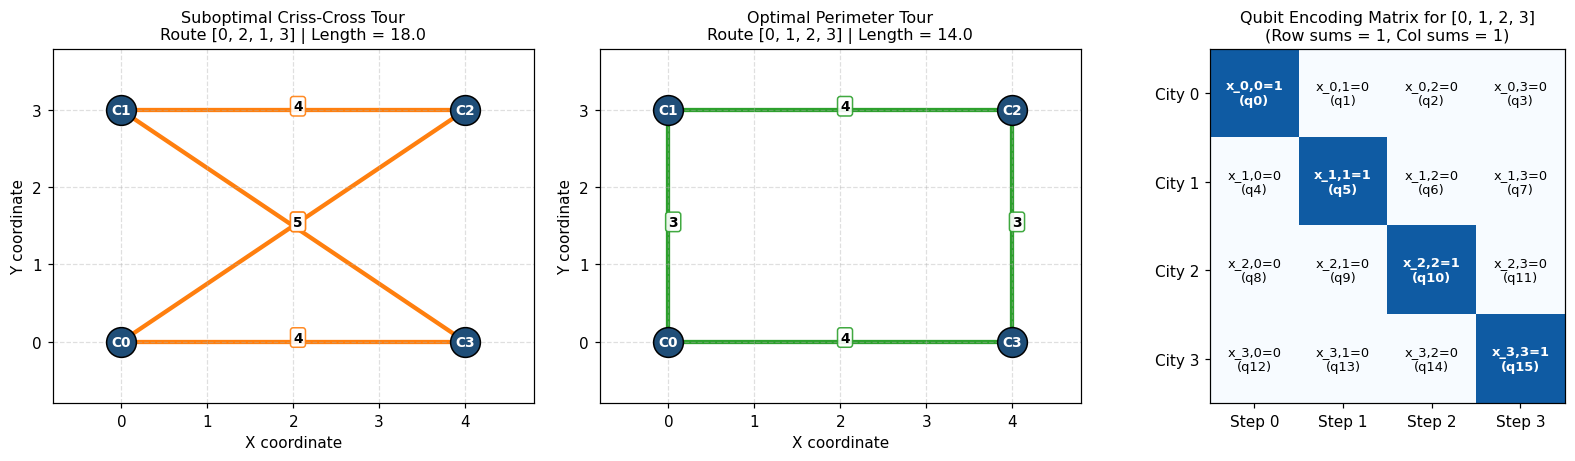

In [ ]:
# Illustration 1: Suboptimal vs. Optimal Tour & Binary Decision Matrix Encoding
def compute_tour_length(tour, pos):
    return sum(
        np.hypot(pos[tour[k]][0] - pos[tour[(k + 1) % len(tour)]][0],
                 pos[tour[k]][1] - pos[tour[(k + 1) % len(tour)]][1])
        for k in range(len(tour))
    )

suboptimal_tour = [0, 2, 1, 3]  # Crosses diagonals (length 18.0)
optimal_tour = [0, 1, 2, 3]     # Outer rectangle perimeter (length 14.0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

# Panel 1 & 2: Geometric comparison of tours
for ax, tour, label, color in [
    (axes[0], suboptimal_tour, "Suboptimal Criss-Cross Tour", "tab:orange"),
    (axes[1], optimal_tour, "Optimal Perimeter Tour", "tab:green"),
]:
    for k in range(n):
        u, v = tour[k], tour[(k + 1) % n]
        ax.plot([coords[u][0], coords[v][0]], [coords[u][1], coords[v][1]],
                color=color, linewidth=2.8, zorder=1)
        mid_x = 0.5 * (coords[u][0] + coords[v][0])
        mid_y = 0.5 * (coords[u][1] + coords[v][1])
        seg_len = np.hypot(coords[u][0] - coords[v][0], coords[u][1] - coords[v][1])
        ax.text(mid_x, mid_y, f"{seg_len:.0f}", fontsize=9, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=color, alpha=0.9))
    for city, (x, y) in coords.items():
        ax.scatter(x, y, s=380, color="#1f4e78", edgecolors="black", zorder=2)
        ax.text(x, y, f"C{city}", color="white", fontsize=9, fontweight="bold",
                ha="center", va="center", zorder=3)
    ax.set_title(f"{label}\nRoute {tour} | Length = {compute_tour_length(tour, coords):.1f}", fontsize=10.5)
    ax.set_xlim(-0.8, 4.8)
    ax.set_ylim(-0.8, 3.8)
    ax.set_xlabel("X coordinate")
    ax.set_ylabel("Y coordinate")
    ax.grid(True, linestyle="--", alpha=0.4)

# Panel 3: Binary Permutation Matrix x_{i,p} for the optimal tour [0, 1, 2, 3]
binary_grid = np.zeros((n, n), dtype=int)
for step, city in enumerate(optimal_tour):
    binary_grid[city, step] = 1

ax_mat = axes[2]
ax_mat.imshow(binary_grid, cmap="Blues", vmin=0, vmax=1.2)
for i in range(n):
    for p in range(n):
        q_idx = i * n + p
        val = binary_grid[i, p]
        txt_color = "white" if val == 1 else "black"
        ax_mat.text(p, i, f"x_{i},{p}={val}\n(q{q_idx})", ha="center", va="center",
                    color=txt_color, fontsize=8.5, fontweight="bold" if val == 1 else "normal")
ax_mat.set_xticks(range(n))
ax_mat.set_xticklabels([f"Step {p}" for p in range(n)])
ax_mat.set_yticks(range(n))
ax_mat.set_yticklabels([f"City {i}" for i in range(n)])
ax_mat.set_title("Qubit Encoding Matrix for [0, 1, 2, 3]\n(Row sums = 1, Col sums = 1)", fontsize=10.5)

plt.tight_layout()
plt.show()

## 3. NetworkX Graph Representation & Classical Exact Reference

We construct a weighted complete undirected graph $G = (V, E)$ in `networkx`, inspect its pairwise distance matrix $D = [d_{ij}]$, and compute the exact classical ground-truth solution by enumerating all $(N-1)! = 6$ tours starting from City `0`.

Pairwise Distance Matrix D:
[[0. 3. 5. 4.]
 [3. 0. 4. 5.]
 [5. 4. 0. 3.]
 [4. 5. 3. 0.]]

All Valid Tours (starting at City 0):
  Route [0, 1, 2, 3] -> Distance: 14.00  <-- OPTIMAL
  Route [0, 1, 3, 2] -> Distance: 16.00
  Route [0, 2, 1, 3] -> Distance: 18.00
  Route [0, 2, 3, 1] -> Distance: 16.00
  Route [0, 3, 1, 2] -> Distance: 18.00
  Route [0, 3, 2, 1] -> Distance: 14.00  <-- OPTIMAL


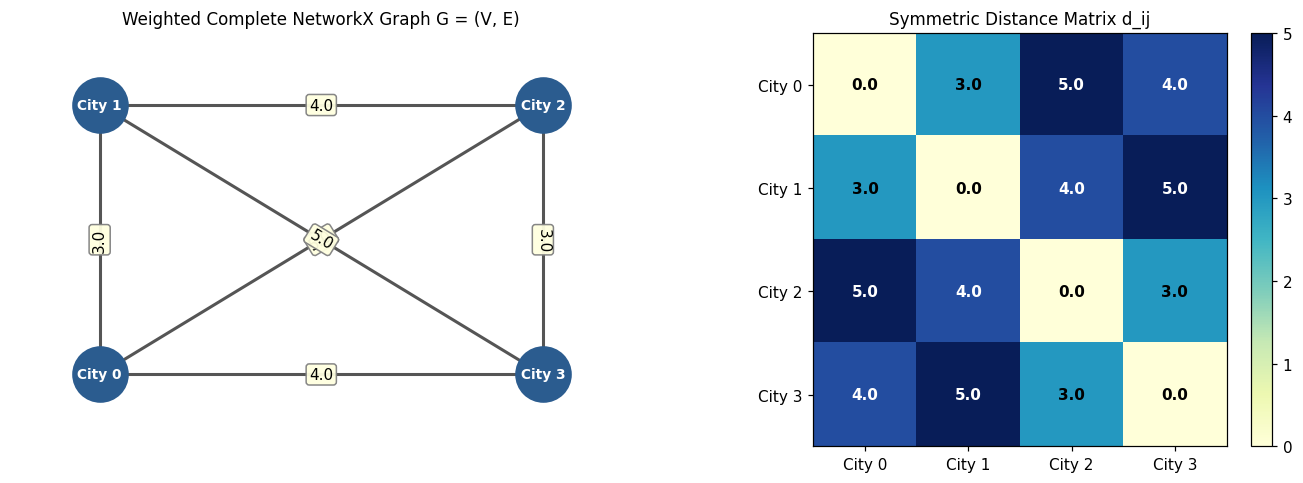

In [ ]:
# Build weighted complete NetworkX graph
G = nx.Graph()
for city, pos in coords.items():
    G.add_node(city, pos=pos)

for i, j in itertools.combinations(range(n), 2):
    dist = round(float(np.hypot(coords[i][0] - coords[j][0], coords[i][1] - coords[j][1])), 2)
    G.add_edge(i, j, weight=dist)

adj_matrix = nx.to_numpy_array(G)
print("Pairwise Distance Matrix D:")
print(adj_matrix)

# Classical exact brute-force search for benchmark verification
start_classical = time.perf_counter()
classical_route = None
classical_cost = float("inf")
all_tours = []

for perm in itertools.permutations(range(1, n)):
    route = [0] + list(perm)
    cost = sum(adj_matrix[route[k], route[(k + 1) % n]] for k in range(n))
    all_tours.append((route, cost))
    if cost < classical_cost:
        classical_cost = cost
        classical_route = route

classical_time = time.perf_counter() - start_classical

print("\nAll Valid Tours (starting at City 0):")
for r, c in all_tours:
    tag = "  <-- OPTIMAL" if np.isclose(c, classical_cost) else ""
    print(f"  Route {r} -> Distance: {c:.2f}{tag}")

# Illustration 2: NetworkX Weighted Graph & Distance Matrix Heatmap
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax_g = axes[0]
nx.draw(
    G, pos=coords, ax=ax_g, with_labels=True,
    labels={i: f"City {i}" for i in G.nodes()},
    node_size=1300, node_color="#2b5c8f", font_color="white",
    font_size=9, font_weight="bold", edge_color="#555555", width=2.0
)
edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(
    G, pos=coords, ax=ax_g, edge_labels=edge_labels, font_size=10,
    bbox=dict(boxstyle="round,pad=0.2", fc="lightyellow", ec="gray", alpha=0.95)
)
ax_g.set_title("Weighted Complete NetworkX Graph G = (V, E)", fontsize=11)
ax_g.set_xlim(-0.8, 4.8)
ax_g.set_ylim(-0.8, 3.8)

ax_d = axes[1]
im = ax_d.imshow(adj_matrix, cmap="YlGnBu")
for i in range(n):
    for j in range(n):
        ax_d.text(j, i, f"{adj_matrix[i, j]:.1f}", ha="center", va="center",
                  color="white" if adj_matrix[i, j] > 3.5 else "black", fontweight="bold")
ax_d.set_xticks(range(n))
ax_d.set_xticklabels([f"City {j}" for j in range(n)])
ax_d.set_yticks(range(n))
ax_d.set_yticklabels([f"City {i}" for i in range(n)])
ax_d.set_title("Symmetric Distance Matrix d_ij", fontsize=11)
fig.colorbar(im, ax=ax_d, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

## 4. Ising Hamiltonian: Mapping to $I$ and $Z$ Gates with New Weightings

### 4.1 Binary-to-Pauli Transformation ($x_q \mapsto \frac{I - Z_q}{2}$)
Each binary variable $x_{i,p} \in \{0, 1\}$ is assigned to qubit $q = i \cdot N + p \in \{0, \dots, 15\}$ and mapped to a spin operator using the identity and Pauli-$Z$ matrices:
$$x_q = \frac{I - Z_q}{2}, \qquad I = \begin{pmatrix} 1 & 0 \\ 0 & 1 \end{pmatrix}, \quad Z = \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix}$$
- Computational basis state $|0\rangle$ has $Z|0\rangle = +1|0\rangle \implies x_q = \frac{1 - 1}{2} = 0$.
- Computational basis state $|1\rangle$ has $Z|1\rangle = -1|1\rangle \implies x_q = \frac{1 - (-1)}{2} = 1$.

### 4.2 How Original Distances & Penalties Become New Hamiltonian Weightings
Substituting $x_q = \frac{I - Z_q}{2}$ into every linear ($w_q x_q$) and quadratic ($Q_{qr} x_q x_r$) QUBO term expands into tensor products of **$I$** and **$Z$** gates:
$$Q_{qr}\, x_q x_r = Q_{qr} \left(\frac{I - Z_q}{2}\right)\left(\frac{I - Z_r}{2}\right) = \underbrace{\frac{Q_{qr}}{4}}_{\text{to } c_0 I} I - \underbrace{\frac{Q_{qr}}{4}}_{\text{to } h_q Z_q} Z_q - \underbrace{\frac{Q_{qr}}{4}}_{\text{to } h_r Z_r} Z_r + \underbrace{\frac{Q_{qr}}{4}}_{\text{to } J_{qr} Z_q Z_r} Z_q Z_r$$

Collecting like Pauli strings yields the **Ising Cost Hamiltonian**:
$$H_{\text{total}} = \underbrace{c_0\, I^{\otimes 16}}_{\text{Identity offset}} + \underbrace{\sum_{q=0}^{15} h_q\, Z_q}_{\text{1-qubit } Z \text{ weights}} + \underbrace{\sum_{0 \le q < r < 16} J_{qr}\, Z_q Z_r}_{\text{2-qubit } Z \otimes Z \text{ couplings}}$$

Notice how the **new weightings** $(c_0, h_q, J_{qr})$ arise:
- **$c_0$ (Global $I^{\otimes 16}$ weighting):** Constant energy baseline absorbing all $I$ contributions.
- **$h_q$ (Single-qubit $Z_q$ weightings):** Local magnetic-field biases combining adjacent tour-edge distances and row/column constraint penalties.
- **$J_{qr}$ (Two-qubit $Z_q Z_r$ weightings):**
  - When qubits $q=(i,p)$ and $r=(j,p+1)$ represent consecutive steps for distinct cities $i \neq j$, $J_{qr} = \frac{d_{ij}}{4}$ (directly encoding the re-scaled edge weights $0.75, 1.00, 1.25$).
  - When qubits $q$ and $r$ share the same city ($i=j$) or same step ($p=p'$), $J_{qr} = \frac{A}{2}$ (penalizing invalid duplicate visits).

In [ ]:
# Step 1: Build QuadraticProgram from NetworkX graph and convert to QUBO
tsp = Tsp(G)
quad_prog = tsp.to_quadratic_program()

conv = QuadraticProgramToQubo()
qubo = conv.convert(quad_prog)

# Step 2: Map QUBO to Ising Hamiltonian composed of I and Z Pauli strings
ising_op, offset = qubo.to_ising()

print(f"Total Qubits: {ising_op.num_qubits}")
print(f"Total Pauli Terms in ising_op (excluding global I): {len(ising_op)}")
print(f"Global Identity Term Weighting (c_0 * I^16): {offset:.4f}")

# Separate 1-local (Z_q) and 2-local (Z_q Z_r) terms and inspect their new weightings
one_local_terms = []
two_local_terms = []
J_matrix = np.zeros((ising_op.num_qubits, ising_op.num_qubits))
h_vector = np.zeros(ising_op.num_qubits)

for pauli_label, coeff in zip(ising_op.paulis.to_labels(), ising_op.coeffs):
    weight = float(np.real(coeff))
    # Remember Qiskit uses little-endian bit ordering: rightmost char is qubit 0
    z_positions = [idx for idx, ch in enumerate(reversed(pauli_label)) if ch == "Z"]
    if len(z_positions) == 1:
        q = z_positions[0]
        h_vector[q] = weight
        one_local_terms.append((pauli_label, f"Z_{q}", weight))
    elif len(z_positions) == 2:
        q, r = z_positions
        J_matrix[q, r] = weight
        J_matrix[r, q] = weight
        two_local_terms.append((pauli_label, f"Z_{q} Z_{r}", weight))

print(f"\n1-Qubit Z_q Terms ({len(one_local_terms)} terms) — Sample:")
for p_str, name, w in one_local_terms[:6]:
    print(f"  {p_str}  ({name:<5}) -> new weight h_q = {w:+.4f}")

print(f"\n2-Qubit Z_q Z_r Terms ({len(two_local_terms)} terms) — Unique Weightings:")
unique_2q_weights = sorted(set(round(w, 4) for _, _, w in two_local_terms))
for uw in unique_2q_weights:
    count = sum(1 for _, _, w in two_local_terms if np.isclose(w, uw))
    role = "Constraint penalty coupling (A / 2)" if uw > 5 else f"Edge distance coupling (d_ij / 4 = {uw*4:.1f} / 4)"
    print(f"  Weight J_qr = {uw:+8.4f}  | Count: {count:2d} terms | Role: {role}")

# Verify exact eigenvalue match for the optimal tour state |psi_opt>
opt_bitstring_be = "".join(str(int(city == classical_route[step])) for city in range(n) for step in range(n))
# Reverse to Qiskit little-endian qubit order
opt_state = Statevector.from_label(opt_bitstring_be[::-1])
exact_ising_val = float(np.real(opt_state.expectation_value(ising_op))) + offset
print(f"\nVerification: <psi_opt | (H_Ising + c_0 I) | psi_opt> = {exact_ising_val:.4f} (Matches classical distance {classical_cost:.4f}!)")

Total Qubits: 16
Total Pauli Terms in ising_op (excluding global I): 112
Global Identity Term Weighting (c_0 * I^16): 3136.0000

1-Qubit Z_q Terms (16 terms) — Sample:
  IIIIIIIIIIIIIIIZ  (Z_0  ) -> new weight h_q = -392.0000
  IIIIIIIIIIIIIIZI  (Z_1  ) -> new weight h_q = -392.0000
  IIIIIIIIIIIIIZII  (Z_2  ) -> new weight h_q = -392.0000
  IIIIIIIIIIIIZIII  (Z_3  ) -> new weight h_q = -392.0000
  IIIIIIIIIIIZIIII  (Z_4  ) -> new weight h_q = -392.0000
  IIIIIIIIIIZIIIII  (Z_5  ) -> new weight h_q = -392.0000

2-Qubit Z_q Z_r Terms (96 terms) — Unique Weightings:
  Weight J_qr =  +0.7500  | Count: 16 terms | Role: Edge distance coupling (d_ij / 4 = 3.0 / 4)
  Weight J_qr =  +1.0000  | Count: 16 terms | Role: Edge distance coupling (d_ij / 4 = 4.0 / 4)
  Weight J_qr =  +1.2500  | Count: 16 terms | Role: Edge distance coupling (d_ij / 4 = 5.0 / 4)
  Weight J_qr = +96.5000  | Count: 48 terms | Role: Constraint penalty coupling (A / 2)

Verification: <psi_opt | (H_Ising + c_0 I) | psi_opt

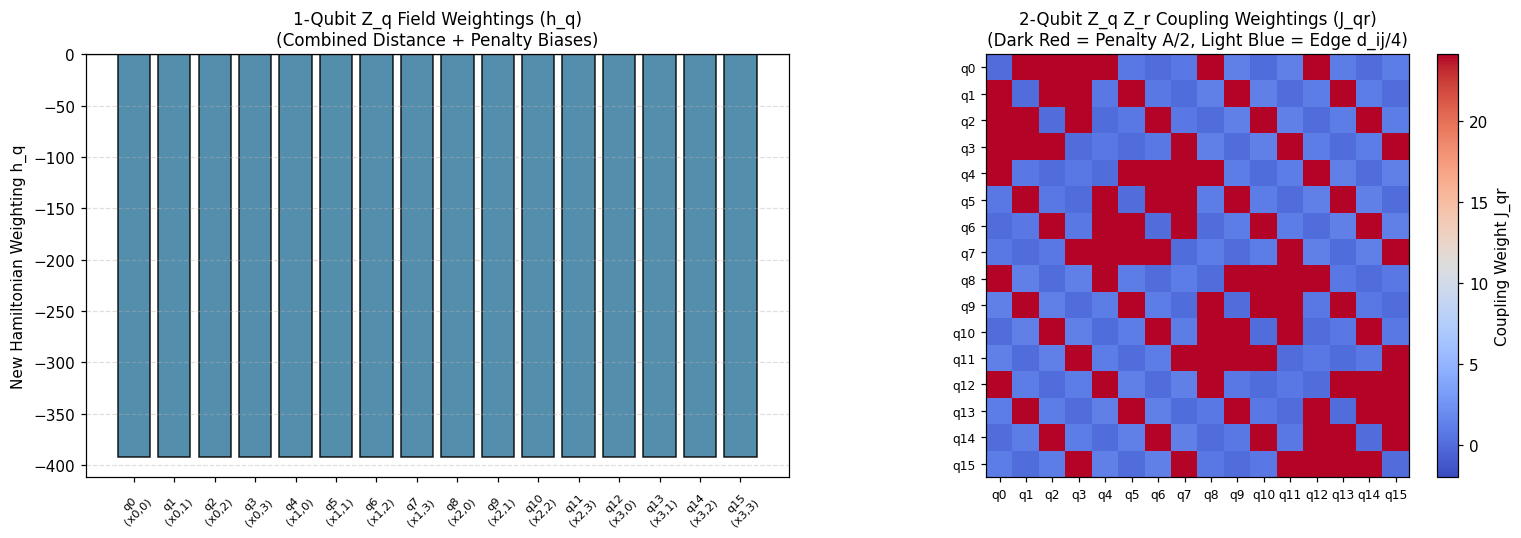

In [ ]:
# Illustration 3: Visualizing the I & Z Hamiltonian Weightings (h_q and J_qr)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left Panel: 1-Qubit Z_q Field Weightings h_q
ax1 = axes[0]
q_indices = np.arange(ising_op.num_qubits)
bars = ax1.bar(q_indices, h_vector, color="#3b7ea1", edgecolor="black", alpha=0.88)
ax1.axhline(0, color="black", linewidth=0.8)
ax1.set_xticks(q_indices)
ax1.set_xticklabels([f"q{q}\n(x{q//n},{q%n})" for q in q_indices], fontsize=7.5, rotation=45)
ax1.set_ylabel("New Hamiltonian Weighting h_q")
ax1.set_title("1-Qubit Z_q Field Weightings (h_q)\n(Combined Distance + Penalty Biases)", fontsize=11)
ax1.grid(True, axis="y", linestyle="--", alpha=0.4)

# Right Panel: 2-Qubit Z_q Z_r Coupling Matrix J_qr
ax2 = axes[1]
im = ax2.imshow(J_matrix, cmap="coolwarm", vmin=-2.0, vmax=max(5.0, J_matrix.max() * 0.25))
ax2.set_xticks(q_indices)
ax2.set_xticklabels([f"q{q}" for q in q_indices], fontsize=8)
ax2.set_yticks(q_indices)
ax2.set_yticklabels([f"q{q}" for q in q_indices], fontsize=8)
ax2.set_title("2-Qubit Z_q Z_r Coupling Weightings (J_qr)\n(Dark Red = Penalty A/2, Light Blue = Edge d_ij/4)", fontsize=11)
cbar = fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)
cbar.set_label("Coupling Weight J_qr")

plt.tight_layout()
plt.show()

## 5. Parameterized Quantum Ansatz & VQE Simulation Setup

To find the ground state of our 16-qubit Ising Hamiltonian $H$, we prepare a variational trial wavefunction $|\psi(\boldsymbol{\theta})\rangle = U(\boldsymbol{\theta})|0\rangle^{\otimes 16}$ using a hardware-efficient **`n_local` ansatz** with:
- Single-qubit $R_y(\theta_k)$ rotation layers (`reps=1`, giving $2 \times 16 = 32$ variational parameters)
- Linear nearest-neighbor $CZ$ entangling gates (`entanglement="linear"`)
- **CVaR-VQE objective (`aggregation=0.25`):** Averages the lowest-energy 25% of sampled bitstrings, dramatically accelerating convergence on combinatorial optimization landscapes.

We will execute and compare **three distinct simulation regimes**:
1. **Statevector Simulation:** Uses exact statevector amplitude simulation (`StatevectorSampler`) with zero gate noise, plus exact analytical statevector evaluation (`Statevector`).
2. **Noiseless Simulation:** Uses shot-based circuit sampling on an ideal `AerSimulator` (`AerSamplerV2` with `shots=1024` and no noise model).
3. **Noisy Simulation:** Uses shot-based circuit sampling on `AerSimulator` (`AerSamplerV2`) with a realistic `NoiseModel` containing single-qubit depolarizing error, two-qubit entangling error, and measurement readout error.

In [ ]:
# Build the 16-qubit variational ansatz circuit
raw_ansatz = n_local(
    ising_op.num_qubits,
    rotation_blocks="ry",
    entanglement_blocks="cz",
    reps=1,
    entanglement="linear"
)

# Transpile once into target ISA basis gates for AerSimulator
aer_backend = AerSimulator()
pass_manager = generate_preset_pass_manager(optimization_level=1, backend=aer_backend)
isa_ansatz = pass_manager.run(raw_ansatz)

print(f"Ansatz Qubits: {raw_ansatz.num_qubits} | Variational Parameters: {raw_ansatz.num_parameters} | Circuit Depth: {raw_ansatz.depth()}")

# Illustration 4: Visualize the Parameterized Quantum Circuit (first 6 qubits for clarity, or full 16 qubits)
fig = raw_ansatz.decompose().draw("mpl", fold=-1, scale=0.65)
fig.suptitle("Parameterized Quantum Circuit (RY + Linear CZ Ansatz, 16 Qubits)", fontsize=12, y=1.02)
plt.show()

Ansatz Qubits: 16 | Variational Parameters: 32 | Circuit Depth: 17


In [ ]:
# Helper utilities to run SamplingVQE and inspect sampled bitstring distributions
def build_sampling_vqe(sampler, ansatz, optimizer, callback, pass_manager=None):
    """Instantiate SamplingVQE cleanly across Qiskit Optimization 0.7+ and 0.6.x."""
    kwargs = dict(
        sampler=sampler,
        ansatz=ansatz,
        optimizer=optimizer,
        aggregation=0.25,
        callback=callback,
    )
    if "pass_manager" in inspect.signature(SamplingVQE.__init__).parameters and pass_manager is not None:
        kwargs["pass_manager"] = pass_manager
    return SamplingVQE(**kwargs)

def decode_and_evaluate(vqe_result, tsp_app, dist_matrix, num_cities):
    route = tsp_app.interpret(vqe_result)
    is_valid = all(isinstance(x, int) for x in route) and len(set(route)) == num_cities
    cost = float(tsp_app.tsp_value(route, dist_matrix)) if is_valid else float("nan")
    return route, is_valid, cost

def extract_top_bitstrings(vqe_result, qubo_problem, tsp_app, num_cities, top_k=5):
    """Extract top sampled bitstrings, probabilities, QUBO energies, and decoded tours."""
    eigenstate = vqe_result.min_eigen_solver_result.eigenstate
    if isinstance(eigenstate, dict):
        items = sorted(eigenstate.items(), key=lambda kv: kv[1], reverse=True)[:top_k]
    else:
        probs = np.abs(np.asarray(eigenstate)) ** 2
        top_indices = np.argsort(probs)[::-1][:top_k]
        items = [(format(idx, f"0{num_cities**2}b"), float(probs[idx])) for idx in top_indices]

    summary = []
    for bitstr, prob in items:
        # Convert Qiskit little-endian bitstring to big-endian binary array
        bits = np.array([int(b) for b in reversed(bitstr)], dtype=int)
        energy = float(qubo_problem.objective.evaluate(bits))
        route = tsp_app.interpret(bits)
        valid = all(isinstance(x, int) for x in route) and len(set(route)) == num_cities
        summary.append((bitstr, prob, energy, route, valid))
    return summary

MAXITER = 120
SHOTS = 1024
print(f"Configured VQE runs with SPSA(maxiter={MAXITER}) and shots={SHOTS}.")

Configured VQE runs with SPSA(maxiter=120) and shots=1024.


### 5.1 Run 1: Statevector Simulation (`StatevectorSampler` & Exact `Statevector`)
First, we run `SamplingVQE` using Qiskit's exact **`StatevectorSampler`**, which evolves the full $2^{16}$-dimensional complex statevector $|\psi(\boldsymbol{\theta})\rangle$ in memory without hardware or gate-level approximations. After optimization, we also construct the exact `Statevector` object at $\boldsymbol{\theta}^*$ to compute the exact analytical expectation value $\langle \psi(\boldsymbol{\theta}^*) | H | \psi(\boldsymbol{\theta}^*) \rangle$.

In [ ]:
def decode_and_evaluate(vqe_result, tsp_app, dist_matrix, num_cities):
    route = tsp_app.interpret(vqe_result)
    is_valid = (
        isinstance(route, (list, tuple))
        and len(route) == num_cities
        and all(isinstance(x, (int, np.integer)) for x in route)
        and len(set(int(x) for x in route)) == num_cities
    )
    route = [int(x) for x in route] if is_valid else route
    cost = float(tsp_app.tsp_value(route, dist_matrix)) if is_valid else float("nan")
    return route, is_valid, cost


def extract_top_bitstrings(vqe_result, qubo_problem, tsp_app, num_cities, top_k=5):
    num_qubits = num_cities**2

    if hasattr(vqe_result, "samples") and vqe_result.samples:
        items = [
            (sample.x, sample.probability)
            for sample in vqe_result.samples
            if getattr(sample, "probability", 0.0) > 0
        ]
    elif (
        hasattr(vqe_result, "min_eigen_solver_result")
        and getattr(vqe_result.min_eigen_solver_result, "eigenstate", None) is not None
    ):
        eigenstate = vqe_result.min_eigen_solver_result.eigenstate
        if hasattr(eigenstate, "binary_probabilities"):
            items = list(eigenstate.binary_probabilities().items())
        elif hasattr(eigenstate, "to_dict"):
            items = list(eigenstate.to_dict().items())
        else:
            items = list(dict(eigenstate).items())
    else:
        items = []

    top_bitstrings = []
    for bitstr, prob in items:
        if isinstance(bitstr, (np.ndarray, list, tuple)):
            bits = np.asarray(bitstr, dtype=int).ravel()
            bitstr_bin = "".join(str(b) for b in reversed(bits))
        elif isinstance(bitstr, (int, np.integer)):
            bitstr_bin = format(int(bitstr), f"0{num_qubits}b")
            bits = np.array([int(b) for b in reversed(bitstr_bin)], dtype=int)
        else:
            bitstr_bin = str(bitstr).zfill(num_qubits)
            bits = np.array([int(b) for b in reversed(bitstr_bin)], dtype=int)

        energy = float(qubo_problem.objective.evaluate(bits))
        route = tsp_app.interpret(bits)
        valid = (
            isinstance(route, (list, tuple))
            and len(route) == num_cities
            and all(isinstance(x, (int, np.integer)) for x in route)
            and len(set(int(x) for x in route)) == num_cities
        )
        route = [int(x) for x in route] if valid else route
        top_bitstrings.append((bitstr_bin, float(prob), energy, route, valid))

    top_bitstrings.sort(key=lambda x: x[1], reverse=True)
    return top_bitstrings[:top_k]


algorithm_globals.random_seed = 42
sv_sampler = StatevectorSampler(default_shots=SHOTS, seed=42)

sv_evals, sv_energies = [], []
def sv_callback(eval_count, parameters, mean, metadata):
    sv_evals.append(eval_count)
    sv_energies.append(mean)

# Keep a measurement-free copy of raw_ansatz so SamplingVQE does not mutate the original
clean_ansatz = raw_ansatz.remove_final_measurements(inplace=False)

sv_vqe = build_sampling_vqe(
    sampler=sv_sampler,
    ansatz=clean_ansatz.copy(),
    optimizer=SPSA(maxiter=MAXITER),
    callback=sv_callback
)
sv_optimizer = MinimumEigenOptimizer(min_eigen_solver=sv_vqe)

t0 = time.perf_counter()
sv_result = sv_optimizer.solve(quad_prog)
sv_time = time.perf_counter() - t0

sv_route, sv_valid, sv_cost = decode_and_evaluate(sv_result, tsp, adj_matrix, n)
sv_top = extract_top_bitstrings(sv_result, qubo, tsp, n)

# Exact analytical statevector expectation value at optimal parameters theta*
opt_params_sv = sv_result.min_eigen_solver_result.optimal_parameters
bound_ansatz = clean_ansatz.assign_parameters(opt_params_sv).remove_final_measurements(inplace=False)
exact_sv_obj = Statevector.from_instruction(bound_ansatz)
exact_sv_energy = float(np.real(exact_sv_obj.expectation_value(ising_op))) + offset

print(f"[1. Statevector Simulation] Route: {sv_route} | Valid: {sv_valid} | Distance: {sv_cost:.2f} | Time: {sv_time:.2f}s")
print(f"    Exact Analytical <psi(theta*)|H|psi(theta*)> = {exact_sv_energy:.4f}")

[1. Statevector Simulation] Route: [1, 2, 3, 0] | Valid: True | Distance: 14.00 | Time: 226.20s
    Exact Analytical <psi(theta*)|H|psi(theta*)> = 997.1367


### 5.2 Run 2: Noiseless Shot-Based Simulation (`AerSamplerV2` Ideal Backend)
Next, we run `SamplingVQE` on an **ideal (noiseless) Qiskit Aer simulator** (`AerSamplerV2` with `shots=1024`). Here, the circuit is transpiled to target basis gates and executed via stochastic shot sampling—capturing pure finite-sample statistical fluctuations without hardware gate or measurement errors.

In [ ]:
algorithm_globals.random_seed = 42
noiseless_sampler = AerSamplerV2(default_shots=SHOTS, seed=42)

noiseless_evals, noiseless_energies = [], []
def noiseless_callback(eval_count, parameters, mean, metadata):
    noiseless_evals.append(eval_count)
    noiseless_energies.append(mean)

noiseless_vqe = build_sampling_vqe(
    sampler=noiseless_sampler,
    ansatz=isa_ansatz,
    optimizer=SPSA(maxiter=MAXITER),
    callback=noiseless_callback,
    pass_manager=pass_manager
)
noiseless_optimizer = MinimumEigenOptimizer(min_eigen_solver=noiseless_vqe)

t0 = time.perf_counter()
noiseless_result = noiseless_optimizer.solve(quad_prog)
noiseless_time = time.perf_counter() - t0

noiseless_route, noiseless_valid, noiseless_cost = decode_and_evaluate(noiseless_result, tsp, adj_matrix, n)
noiseless_top = extract_top_bitstrings(noiseless_result, qubo, tsp, n)

print(f"[2. Noiseless Aer Simulation] Route: {noiseless_route} | Valid: {noiseless_valid} | Distance: {noiseless_cost:.2f} | Time: {noiseless_time:.2f}s")

[2. Noiseless Aer Simulation] Route: [0, 3, 2, 1] | Valid: True | Distance: 14.00 | Time: 16.54s


### 5.3 Run 3: Noisy Hardware Simulation (`AerSamplerV2` + `NoiseModel`)
Finally, we construct a realistic **quantum hardware noise model** (`qiskit_aer.noise.NoiseModel`) incorporating:
- **1-Qubit Gate Depolarizing Error:** $p_{1q} = 0.1\%$ (`0.001`) on single-qubit rotations (`rx`, `ry`, `rz`, `sx`, `x`).
- **2-Qubit Entangling Gate Depolarizing Error:** $p_{2q} = 1.0\%$ (`0.01`) on two-qubit gates (`cz`, `cx`).
- **Measurement Readout Error:** $p_{\text{readout}} = 2.0\%$ (`0.02`) symmetric bit-flip probability during final measurement.

In [ ]:
# Build realistic gate + readout noise model
noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(depolarizing_error(0.001, 1), ["rx", "ry", "rz", "sx", "x"])
noise_model.add_all_qubit_quantum_error(depolarizing_error(0.01, 2), ["cz", "cx"])
noise_model.add_all_qubit_readout_error(ReadoutError([[0.98, 0.02], [0.02, 0.98]]))

print(noise_model)

# Transpile specifically against the noisy backend so all circuit gates match noise_model.basis_gates
noisy_backend = AerSimulator(noise_model=noise_model)
noisy_pass_manager = generate_preset_pass_manager(optimization_level=1, backend=noisy_backend)
noisy_isa_ansatz = noisy_pass_manager.run(raw_ansatz)

algorithm_globals.random_seed = 42
noisy_sampler = AerSamplerV2(
    default_shots=SHOTS,
    seed=42,
    options={"backend_options": {"noise_model": noise_model}}
)

noisy_evals, noisy_energies = [], []
def noisy_callback(eval_count, parameters, mean, metadata):
    noisy_evals.append(eval_count)
    noisy_energies.append(mean)

noisy_vqe = build_sampling_vqe(
    sampler=noisy_sampler,
    ansatz=noisy_isa_ansatz,
    optimizer=SPSA(maxiter=MAXITER),
    callback=noisy_callback,
    pass_manager=noisy_pass_manager
)
noisy_optimizer = MinimumEigenOptimizer(min_eigen_solver=noisy_vqe)

t0 = time.perf_counter()
noisy_result = noisy_optimizer.solve(quad_prog)
noisy_time = time.perf_counter() - t0

noisy_route, noisy_valid, noisy_cost = decode_and_evaluate(noisy_result, tsp, adj_matrix, n)
noisy_top = extract_top_bitstrings(noisy_result, qubo, tsp, n)

print(f"\n[3. Noisy Aer Simulation] Route: {noisy_route} | Valid: {noisy_valid} | Distance: {noisy_cost:.2f} | Time: {noisy_time:.2f}s")

## 6. Comparative Analysis & Illustrations Across All Simulation Regimes

Let's visualize how **Statevector**, **Noiseless**, and **Noisy** simulations behave across:
1. **Energy Convergence Trajectories** during SPSA optimization.
2. **Top Sampled Quantum States** (probabilities and decoded tour validity).
3. **Discovered Tours Overlaid on the NetworkX Graph**.

In [ ]:
# Illustration 5: VQE Convergence Curves & Top Sampled State Probabilities
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel A: VQE Convergence Comparison
ax_conv = axes[0]
ax_conv.plot(sv_evals, sv_energies, label="1. Statevector Simulation", color="#1b7837", linewidth=2.2)
ax_conv.plot(noiseless_evals, noiseless_energies, label="2. Noiseless Aer Simulation", color="#2166ac", linewidth=2.0, linestyle="-.")
ax_conv.plot(noisy_evals, noisy_energies, label="3. Noisy Aer Simulation (Gate + Readout)", color="#d73027", linewidth=1.8, alpha=0.85)
ax_conv.plot(sv_evals, np.array(sv_energies) + offset, label="1. Statevector Simulation", color="#1b7837", linewidth=2.2)
ax_conv.plot(noiseless_evals, np.array(noiseless_energies) + offset, label="2. Noiseless Aer Simulation", color="#2166ac", linewidth=2.0, linestyle="-.")
ax_conv.plot(noisy_evals, np.array(noisy_energies) + offset, label="3. Noisy Aer Simulation (Gate + Readout)", color="#d73027", linewidth=1.8, alpha=0.85)
ax_conv.axhline(classical_cost, color="black", linestyle="--", linewidth=1.3, label=f"Exact Ground Energy ({classical_cost:.1f})")
ax_conv.set_xlabel("SPSA Function Evaluation Count")
ax_conv.set_ylabel("CVaR Expectation Value (Energy)")
ax_conv.set_title("VQE Convergence: Statevector vs. Noiseless vs. Noisy", fontsize=11.5)
ax_conv.legend(loc="upper right", fontsize=9)
ax_conv.grid(True, linestyle="--", alpha=0.4)

# Panel B: Top-4 Sampled Tour Probabilities per Regime
ax_prob = axes[1]
regimes = [
    ("Statevector", sv_top, "#1b7837"),
    ("Noiseless", noiseless_top, "#2166ac"),
    ("Noisy", noisy_top, "#d73027"),
]
x_pos = np.arange(4)
bar_w = 0.25

for idx, (name, top_list, color) in enumerate(regimes):
    probs = [item[1] for item in top_list[:4]]
    while len(probs) < 4:
        probs.append(0.0)
    rects = ax_prob.bar(x_pos + (idx - 1) * bar_w, probs, width=bar_w, label=name, color=color, alpha=0.88, edgecolor="black")
    for rect, item in zip(rects, top_list[:4]):
        _, prob, _, route, valid = item
        tag = f"{route}" if valid else "Invalid"
        if prob > 0.03:
            ax_prob.text(rect.get_x() + rect.get_width() / 2, prob + 0.01, f"{prob:.2f}\n{tag}",
                         ha="center", va="bottom", fontsize=7.2, rotation=0)

ax_prob.set_xticks(x_pos)
ax_prob.set_xticklabels(["Rank 1 State", "Rank 2 State", "Rank 3 State", "Rank 4 State"])
ax_prob.set_ylabel("Measurement Probability")
ax_prob.set_ylim(0, min(1.15, max(0.35, max([t[0][1] for _, t, _ in regimes if t]) + 0.22)))
ax_prob.set_title("Top-4 Sampled Bitstring Probabilities by Simulation Mode", fontsize=11.5)
ax_prob.legend(fontsize=9)
ax_prob.grid(True, axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [ ]:
# Summary Benchmark Table & Illustration 6: Discovered Tours on NetworkX Graph
print("=" * 86)
print(f"{'Simulation / Solver Regime':<32} | {'Discovered Route':<18} | {'Valid':<6} | {'Distance':<10} | {'Time (s)':<8}")
print("-" * 86)
print(f"{'Classical Exact (Reference)':<32} | {str(classical_route):<18} | {'True':<6} | {classical_cost:<10.2f} | {classical_time:<8.4f}")
print(f"{'1. Quantum VQE (Statevector)':<32} | {str(sv_route):<18} | {str(sv_valid):<6} | {sv_cost:<10.2f} | {sv_time:<8.2f}")
print(f"{'2. Quantum VQE (Noiseless Aer)':<32} | {str(noiseless_route):<18} | {str(noiseless_valid):<6} | {noiseless_cost:<10.2f} | {noiseless_time:<8.2f}")
print(f"{'3. Quantum VQE (Noisy Aer)':<32} | {str(noisy_route):<18} | {str(noisy_valid):<6} | {noisy_cost:<10.2f} | {noisy_time:<8.2f}")
print("=" * 86)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
tour_runs = [
    ("1. Statevector Simulation", sv_route, sv_valid, sv_cost, "#1b7837"),
    ("2. Noiseless Aer Simulation", noiseless_route, noiseless_valid, noiseless_cost, "#2166ac"),
    ("3. Noisy Aer Simulation", noisy_route, noisy_valid, noisy_cost, "#d73027"),
]
edge_labels = nx.get_edge_attributes(G, "weight")

for ax, (title, route, is_valid, cost, color) in zip(axes, tour_runs):
    nx.draw(
        G, pos=coords, ax=ax, with_labels=True,
        labels={i: f"C{i}" for i in G.nodes()},
        node_size=900, node_color="#1f4e78", font_color="white",
        font_weight="bold", edge_color="lightgray", width=1.5
    )
    nx.draw_networkx_edge_labels(G, pos=coords, ax=ax, edge_labels=edge_labels, font_size=9)
    if is_valid:
        tour_edges = [(route[k], route[(k + 1) % n]) for k in range(n)]
        nx.draw_networkx_edges(G, pos=coords, ax=ax, edgelist=tour_edges, width=3.5, edge_color=color)
        status_str = "OPTIMAL" if np.isclose(cost, classical_cost) else "SUBOPTIMAL"
        ax.set_title(f"{title}\nRoute: {route} | Dist: {cost:.1f} ({status_str})", fontsize=10.5)
    else:
        ax.set_title(f"{title}\nConstraint Violated: {route}", fontsize=10.5, color="#d73027")
    ax.set_xlim(-0.8, 4.8)
    ax.set_ylim(-0.8, 3.8)

plt.tight_layout()
plt.show()